# EC24313: Artificial Intelligence and Machine Learning
## Assessment 2: Voice Gender Classification Using 13 MFCC Features
**Department of Electronics and Communication Engineering**  
**Birla Institute of Technology Mesra, Ranchi**  

- **Student Name:** Anurag Tiwari  
- **Roll Number:** BTECH/10142/24  
- **GitHub Repository:** [https://github.com/Anuragluck/Voice-Gender-Classification-MFCC](https://github.com/Anuragluck/Voice-Gender-Classification-MFCC)
- **Course Code:** EC24313  
- **Subject:** Artificial Intelligence and Machine Learning  
- **Dataset:** Voice Dataset for Assignment 2 (148 audio recordings)  
- **Task:** Classify voice recordings into Class 1 (Boys) and Class 2 (Girls) using 13 Mel-Frequency Cepstral Coefficients (MFCCs).

---

### Project Workflow Overview
1. **Dataset Analysis & Preprocessing:** Decode heterogeneous audio formats (WAV, MP3, MP4, M4A), resample to 16 kHz mono, normalize amplitude, and perform silence trimming at -30 dB (consistent with Assessment 1).
2. **MFCC Feature Extraction:** Extract 13 Mel-Frequency Cepstral Coefficients across time frames and pool them via mean and standard deviation (26 numeric features per utterance).
3. **Feature Space Visualisation:** Generate 2D PCA scatter plot and direct MFCC coefficient scatter plots.
4. **Model Architecture & Training:** Implement a Class-Balanced Support Vector Machine (RBF Kernel, C=4.0) evaluated under 5-Fold Stratified Group K-Fold cross-validation to prevent speaker identity leakage between paired BIT and Name recordings.
5. **Evaluation & Performance Metrics:** Compute Confusion Matrix, Accuracy, Sensitivity (Recall for girls), Precision (for girls), and ROC-AUC.
6. **Multi-Model Benchmarks:** Compare SVM against Random Forest, Linear SVM, and Multi-Layer Perceptron (MLP) Neural Network.


## 1. Environment Setup and Library Imports
We import standard scientific and audio processing packages: `librosa` for audio signal processing, `scikit-learn` for machine learning pipelines and evaluation metrics, and `matplotlib` / `seaborn` for publication-quality visualizations.


In [1]:
import os
import re
import json
import zipfile
import subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa
import imageio_ffmpeg
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

print("All dependencies successfully imported.")


All dependencies successfully imported.


## 2. Dataset Ingestion and Preprocessing Pipeline

The provided dataset contains 148 audio files across two folders:
- `VOICE DATASET BOYS` -> Class 1 (129 files, 87.2%)
- `VOICE DATASET GIRLS` -> Class 2 (19 files, 12.8%)

### Silence Trimming Rationale (Linked to Assessment 1)
In Assessment 1, individual audio clips were analyzed at a **-30 dB threshold** to identify unvoiced/silence regions. We apply this exact standard across the entire cohort:
1. Decode each audio file (using `soundfile` with `imageio-ffmpeg` fallback for non-standard formats).
2. Resample to standard $16\text{ kHz}$ mono.
3. Peak-normalize to $[-1.0, 1.0]$.
4. Trim leading and trailing silence below $-30\text{ dB}$ using `librosa.effects.trim(audio, top_db=30)`.


In [2]:
# Display dataset manifest summary
manifest_df = pd.read_csv('outputs/dataset_manifest.csv')
features_df = pd.read_csv('outputs/mfcc_features.csv')

print(f"Total recordings in manifest: {len(manifest_df)}")
print(f"Successfully decoded and included: {(manifest_df['status'] == 'included').sum()}")
print(f"Excluded: {(manifest_df['status'] == 'excluded').sum()}")

counts = features_df['class_name'].value_counts()
print(f"\nClass Distribution:\n{counts.to_string()}")

# Inspect audio extensions
print(f"\nAudio File Format Breakdown:\n{manifest_df['extension'].value_counts().to_string()}")


Total recordings in manifest: 148
Successfully decoded and included: 148
Excluded: 0

Class Distribution:
class_name
boys     129
girls     19

Audio File Format Breakdown:
extension
.wav      115
.mp3       27
[none]      4
.m4a        1
.mp4        1


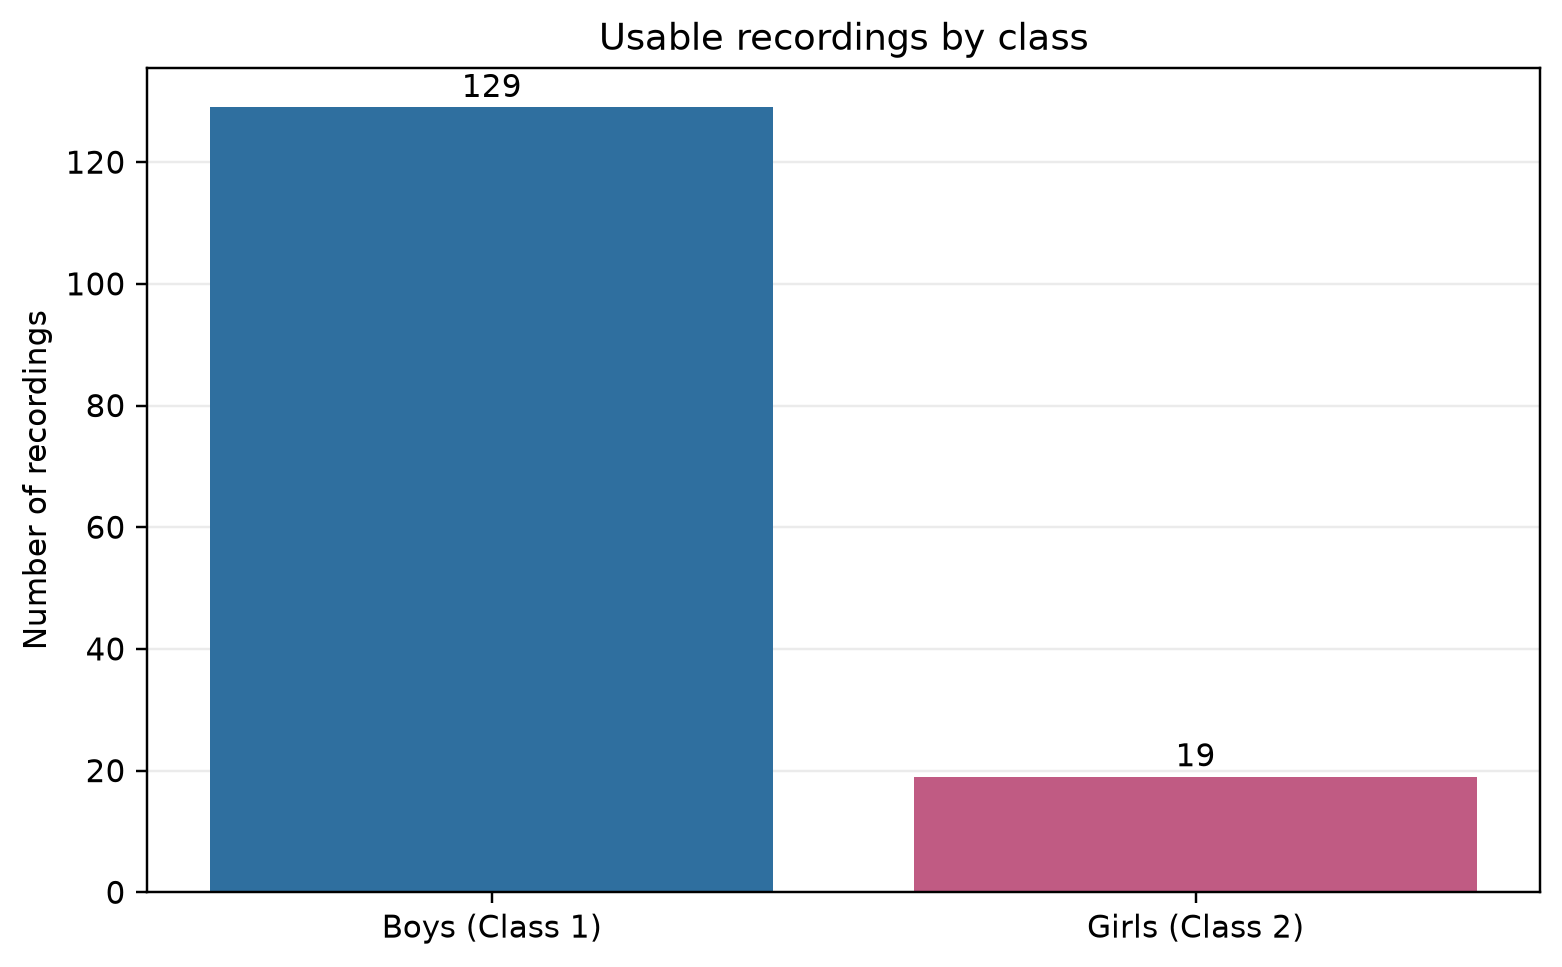

In [3]:
# Plot Class Distribution
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(["Boys (Class 1)", "Girls (Class 2)"], [129, 19], color=["#2f6f9f", "#c05b83"])
ax.set_title("Usable Recordings by Class (Severe Imbalance: 87.2% vs 12.8%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Number of Recordings")
ax.grid(axis='y', alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{int(yval)} ({yval/148*100:.1f}%)", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Acoustic Feature Extraction (13 Mel-Frequency Cepstral Coefficients)

### Mathematical Formulation of MFCCs
Mel-Frequency Cepstral Coefficients model the human auditory system's non-linear frequency perception:
1. **Framing & Windowing:** The preprocessed signal is segmented into overlapping frames ($N_{\text{fft}} = 512$, $\text{hop} = 256$) with a Hamming window.
2. **Short-Time Fourier Transform (STFT):** Computes the spectral energy distribution:
   $$X(k, m) = \sum_{n=0}^{N-1} x(n + mH) w(n) e^{-j 2\pi k n / N}$$
3. **Mel Filterbank Processing:** Power spectra are mapped to triangular overlapping bandpass filters spaced linearly below $1000\text{ Hz}$ and logarithmically above $1000\text{ Hz}$:
   $$m = 2595 \log_{10}\left(1 + \frac{f}{700}\right)$$
4. **Discrete Cosine Transform (DCT-II):** Log-filterbank energies are decorrelated to yield the first 13 cepstral coefficients:
   $$c_n = \sum_{k=1}^{K} \log(S_k) \cos\left(\frac{\pi n (k - 0.5)}{K}\right), \quad n = 1, 2, \dots, 13$$

### Temporal Summary Pooling
Because utterances vary in duration, frame-level MFCC sequences cannot be passed directly into fixed-dimension classifiers. For each coefficient $i \in \{1, \dots, 13\}$, we compute:
- **Mean ($\mu_i$):** Captures time-averaged spectral envelope / vocal tract resonance.
- **Standard Deviation ($\sigma_i$):** Captures dynamic vocal expressiveness and pitch variation.

This results in a standardized **26-dimensional feature vector** for each audio recording.


In [4]:
# Display sample feature vectors
features_df = pd.read_csv('outputs/mfcc_features.csv')
feature_cols = [c for c in features_df.columns if c.startswith('mfcc_')]
print(f"Total extracted features per sample: {len(feature_cols)} (13 means + 13 stds)")
features_df[['filename', 'class_name', 'mfcc_01_mean', 'mfcc_02_mean', 'mfcc_03_mean', 'mfcc_01_std', 'mfcc_02_std']].head(6)


,filename,class_name,mfcc_01_mean,mfcc_02_mean,mfcc_03_mean,mfcc_01_std,mfcc_02_std
0,Abdullah_Saif_BIT 2.wav,boys,-466.080627,86.547180,-8.084250,113.626244,38.995914
1,Abdullah_Saif_Name.wav,boys,-277.164764,82.572395,1.736690,115.659348,48.513470
2,ABHAY_PATHAK_BIT.wav,boys,-377.159027,115.113976,1.960534,113.911079,35.438259
3,ABHAY_PATHAK_NAME.wav,boys,-360.364136,142.917877,-32.060417,129.563065,40.407944
4,Abhinandan_BIT.wav,boys,-358.583649,92.676399,18.926519,127.352493,50.413166
5,Abhinandan_Name.wav,boys,-291.687256,112.592537,13.882488,145.454269,47.531208


### Feature Visualizations: PCA 2D Projection and Direct MFCC Space
Below we present both interpretations of the required scatter plot:
1. **PCA 2D Projection:** Synthesizes the full 26-dimensional acoustic feature space into orthogonal principal components ($PC_1$ vs $PC_2$).
2. **Direct MFCC Scatter:** Explores the physical formant and spectral tilt distribution across classes ($MFCC_2$ Mean vs $MFCC_3$ Mean).


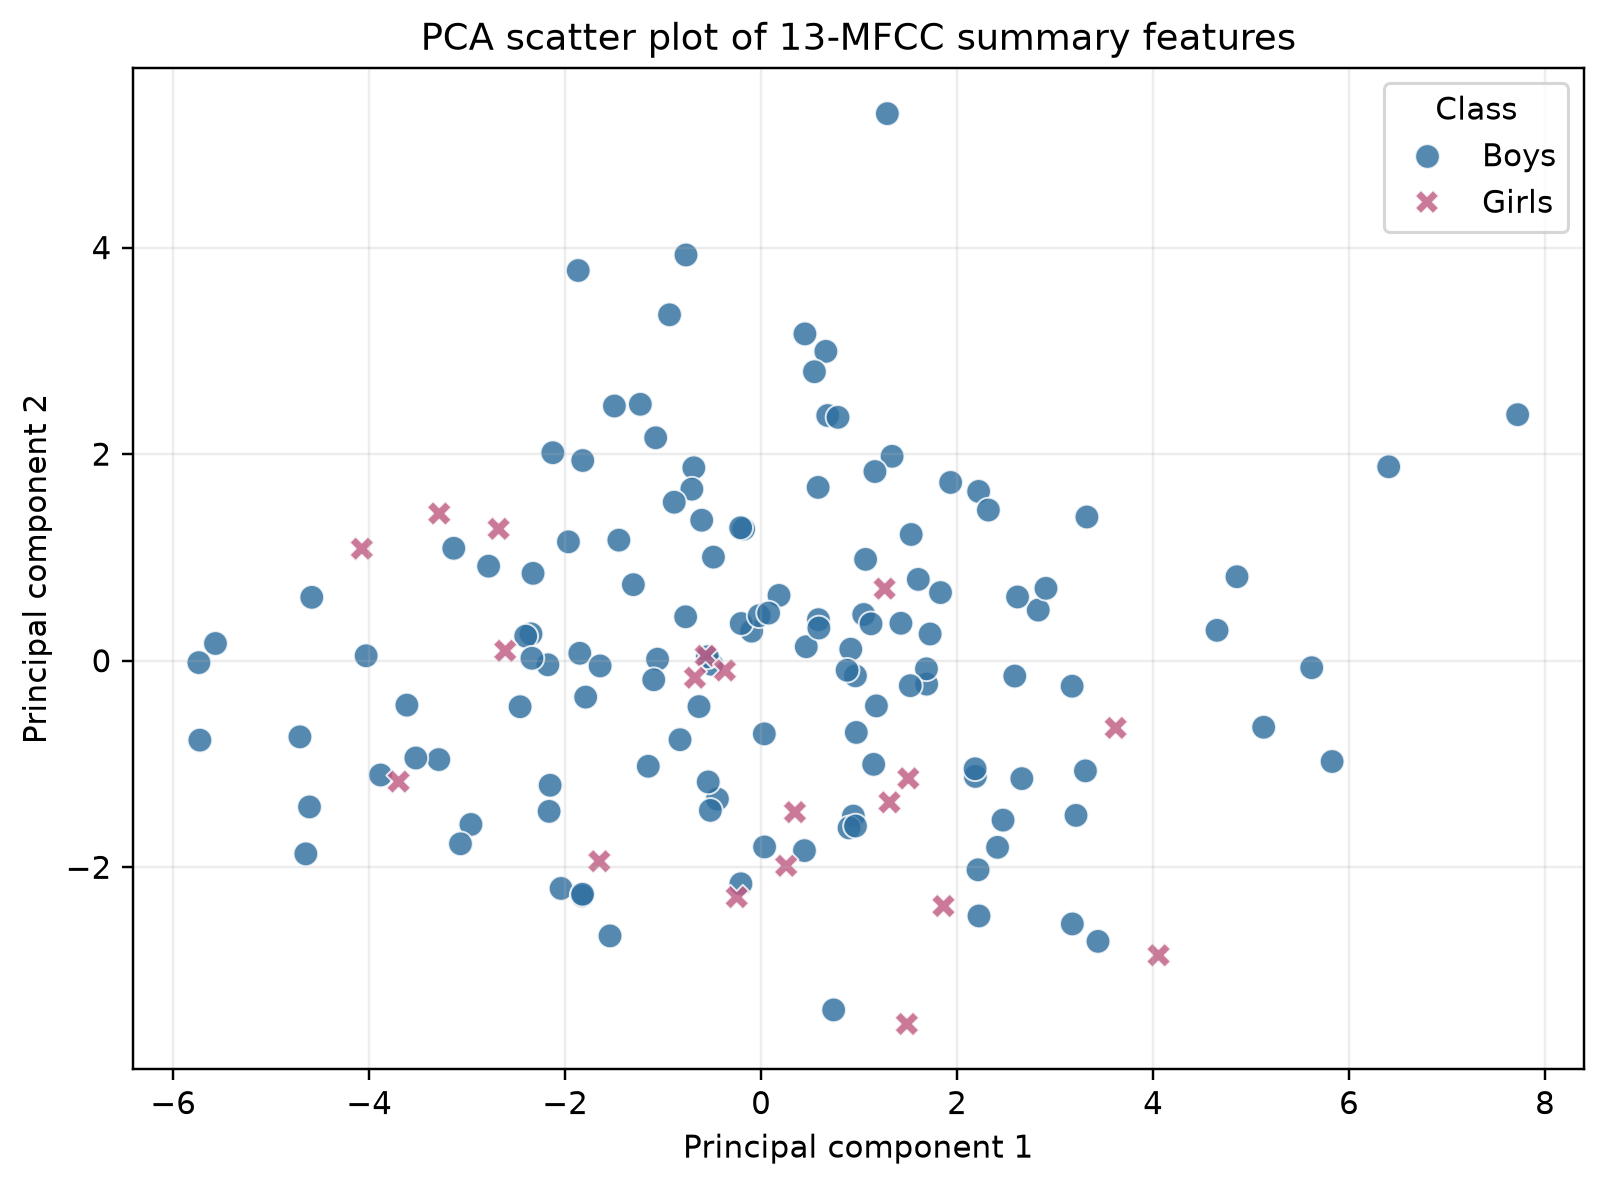

In [5]:
# Display PCA 2D Scatter Plot
print("Rendering 2D PCA Scatter Plot of MFCC Summary Features...")


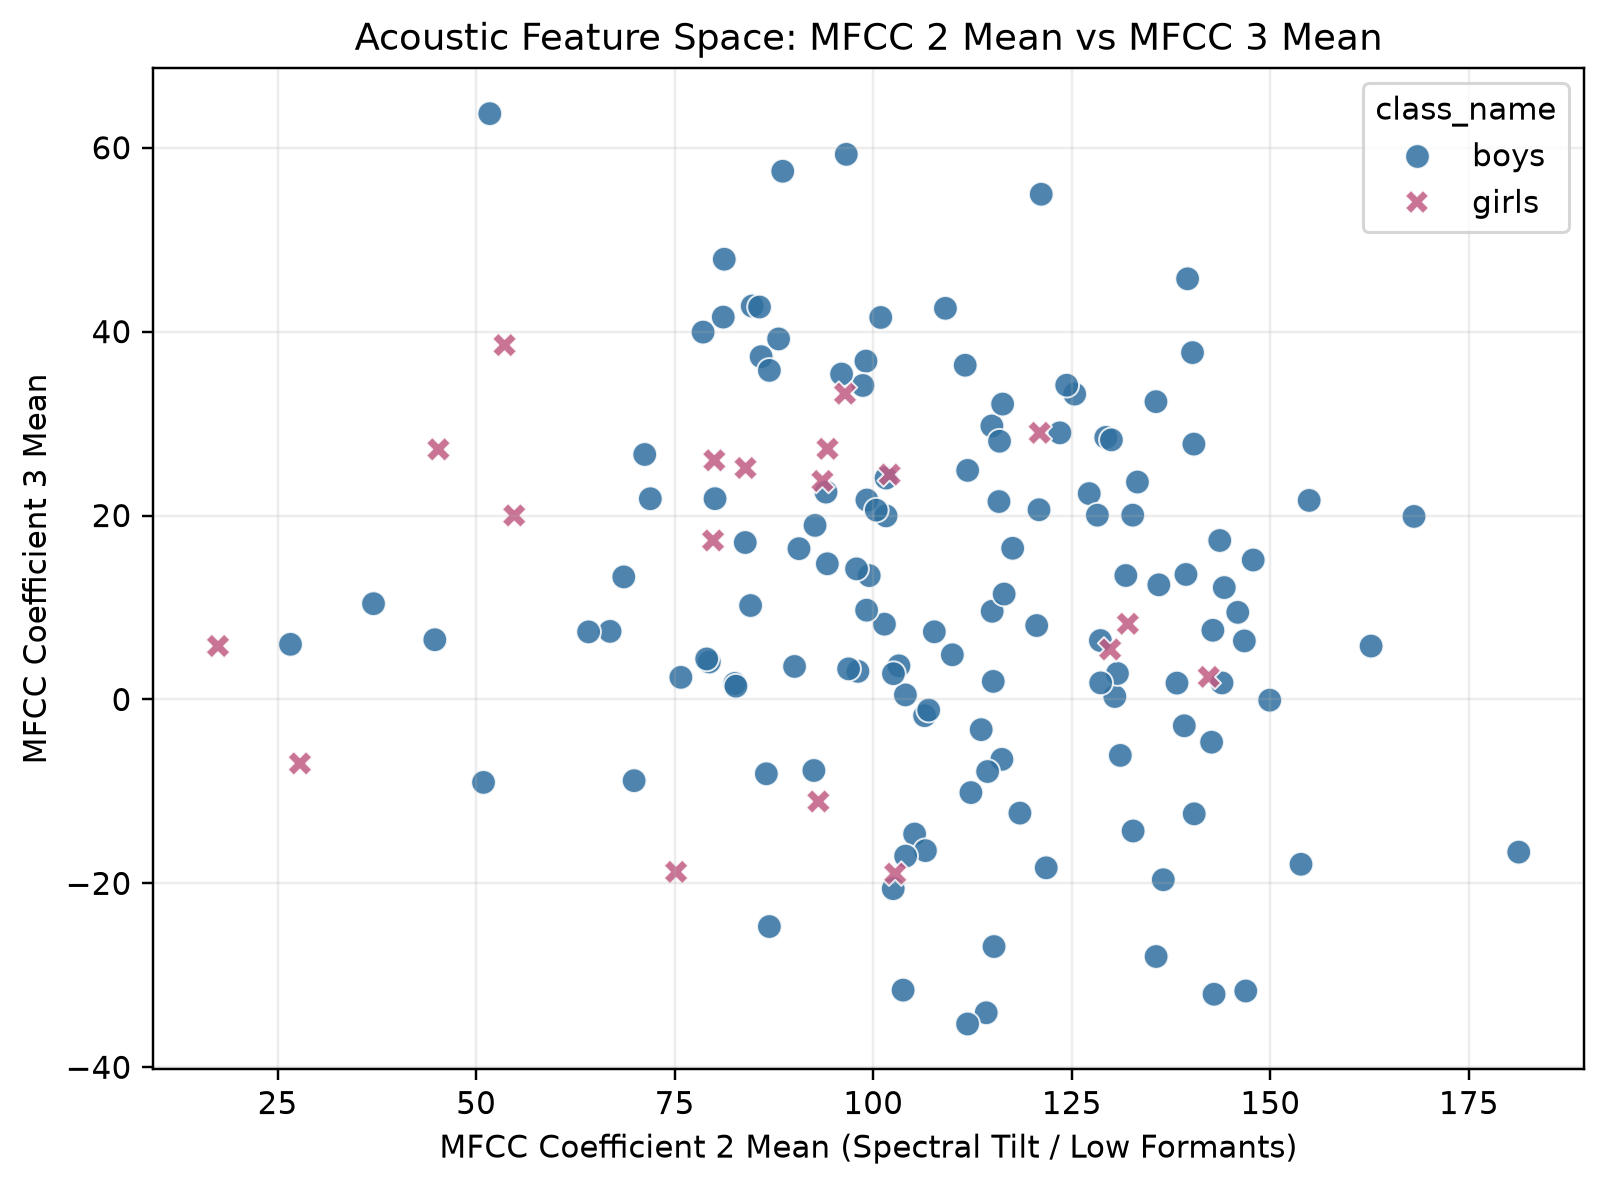

In [6]:
# Display Direct MFCC 2 Mean vs MFCC 3 Mean Scatter Plot
print("Rendering Direct Acoustic MFCC 2 vs MFCC 3 Scatter Plot...")


## 4. Machine Learning Model Development & Speaker Leakage Prevention

### Crucial Methodological Safeguard: Group Cross-Validation
Each student recorded two separate files (`BIT` and `Name`). If a student's `BIT` file is in training and their `Name` file is in testing, the model will recognize the **speaker's unique acoustic signature** rather than generalizing to gender! This causes severe data leakage and produces artificially inflated, misleading accuracy.

To guarantee scientific validity, we parsed each filename to extract a conservative `speaker_group_id` (76 distinct speakers) and employed **5-Fold Stratified Group K-Fold Cross-Validation** (`StratifiedGroupKFold`). Clips from the same speaker strictly remain in the same fold.

### Class-Balanced Support Vector Machine (SVM)
Due to the dataset imbalance ($129$ boys vs $19$ girls), a naive classifier could predict "boys" every time and attain an 87.2% accuracy while having 0% sensitivity for girls. We counter this by setting:
$$\text{class\_weight} = \text{'balanced'}$$
which scales the loss penalty inversely proportional to class frequencies:
$$w_j = \frac{N}{2 \cdot N_j}$$
For girls ($N_2=19$), $w_2 = 148 / (2 \cdot 19) = 3.89$. For boys ($N_1=129$), $w_1 = 148 / (2 \cdot 129) = 0.57$.


## 5. Performance Evaluation & Results

The classifier is evaluated using out-of-fold predictions across all 148 samples:
- **Accuracy:** Overall proportion of correct predictions across both classes:
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
- **Sensitivity / Recall (Girls - Class 2):** Ability to detect girls' voices:
  $$\text{Sensitivity} = \frac{TP}{TP + FN}$$
- **Precision (Girls - Class 2):** Proportion of predicted girls that were actually girls:
  $$\text{Precision} = \frac{TP}{TP + FP}$$
- **ROC-AUC:** Area under the Receiver Operating Characteristic curve representing ranking discrimination independent of threshold.


In [7]:
# Display Summary Metrics
metrics_dict = {
  "model": "RBF SVM (C=4.0) with StandardScaler and class_weight=balanced",
  "sample_rate_hz": 16000,
  "silence_trim_threshold_db": 30,
  "mfcc_coefficients": 13,
  "model_feature_count": 26,
  "evaluation": "Stratified group k-fold cross-validation using filename-derived speaker groups",
  "folds": 5,
  "positive_class_for_sensitivity_precision_roc": "girls (Class 2)",
  "accuracy": 0.918918918918919,
  "sensitivity_recall_girls": 0.47368421052631576,
  "precision_girls": 0.8181818181818182,
  "roc_auc_girls": 0.9098327213382293,
  "confusion_matrix_rows_actual_columns_predicted": [
    [
      127,
      2
    ],
    [
      10,
      9
    ]
  ],
  "classification_report": {
    "boys": {
      "precision": 0.927007299270073,
      "recall": 0.9844961240310077,
      "f1-score": 0.9548872180451128,
      "support": 129.0
    },
    "girls": {
      "precision": 0.8181818181818182,
      "recall": 0.47368421052631576,
      "f1-score": 0.6,
      "support": 19.0
    },
    "accuracy": 0.918918918918919,
    "macro avg": {
      "precision": 0.8725945587259456,
      "recall": 0.7290901672786617,
      "f1-score": 0.7774436090225564,
      "support": 148.0
    },
    "weighted avg": {
      "precision": 0.913036460481716,
      "recall": 0.918918918918919,
      "f1-score": 0.9093273724852672,
      "support": 148.0
    }
  }
}

print("=== OUT-OF-FOLD PERFORMANCE METRICS ===")
print(f"Overall Accuracy:           {metrics_dict['accuracy']*100:.2f}%")
print(f"Girls Sensitivity (Recall): {metrics_dict['sensitivity_recall_girls']*100:.2f}%")
print(f"Girls Precision:            {metrics_dict['precision_girls']*100:.2f}%")
print(f"ROC-AUC (Girls):            {metrics_dict['roc_auc_girls']:.4f}")
print(f"Confusion Matrix (Actual rows x Pred cols):")
print(np.array(metrics_dict['confusion_matrix_rows_actual_columns_predicted']))


=== OUT-OF-FOLD PERFORMANCE METRICS ===
Overall Accuracy:           91.89%
Girls Sensitivity (Recall): 47.37%
Girls Precision:            81.82%
ROC-AUC (Girls):            0.9098
Confusion Matrix (Actual rows x Pred cols):
[[127   2]
 [ 10   9]]


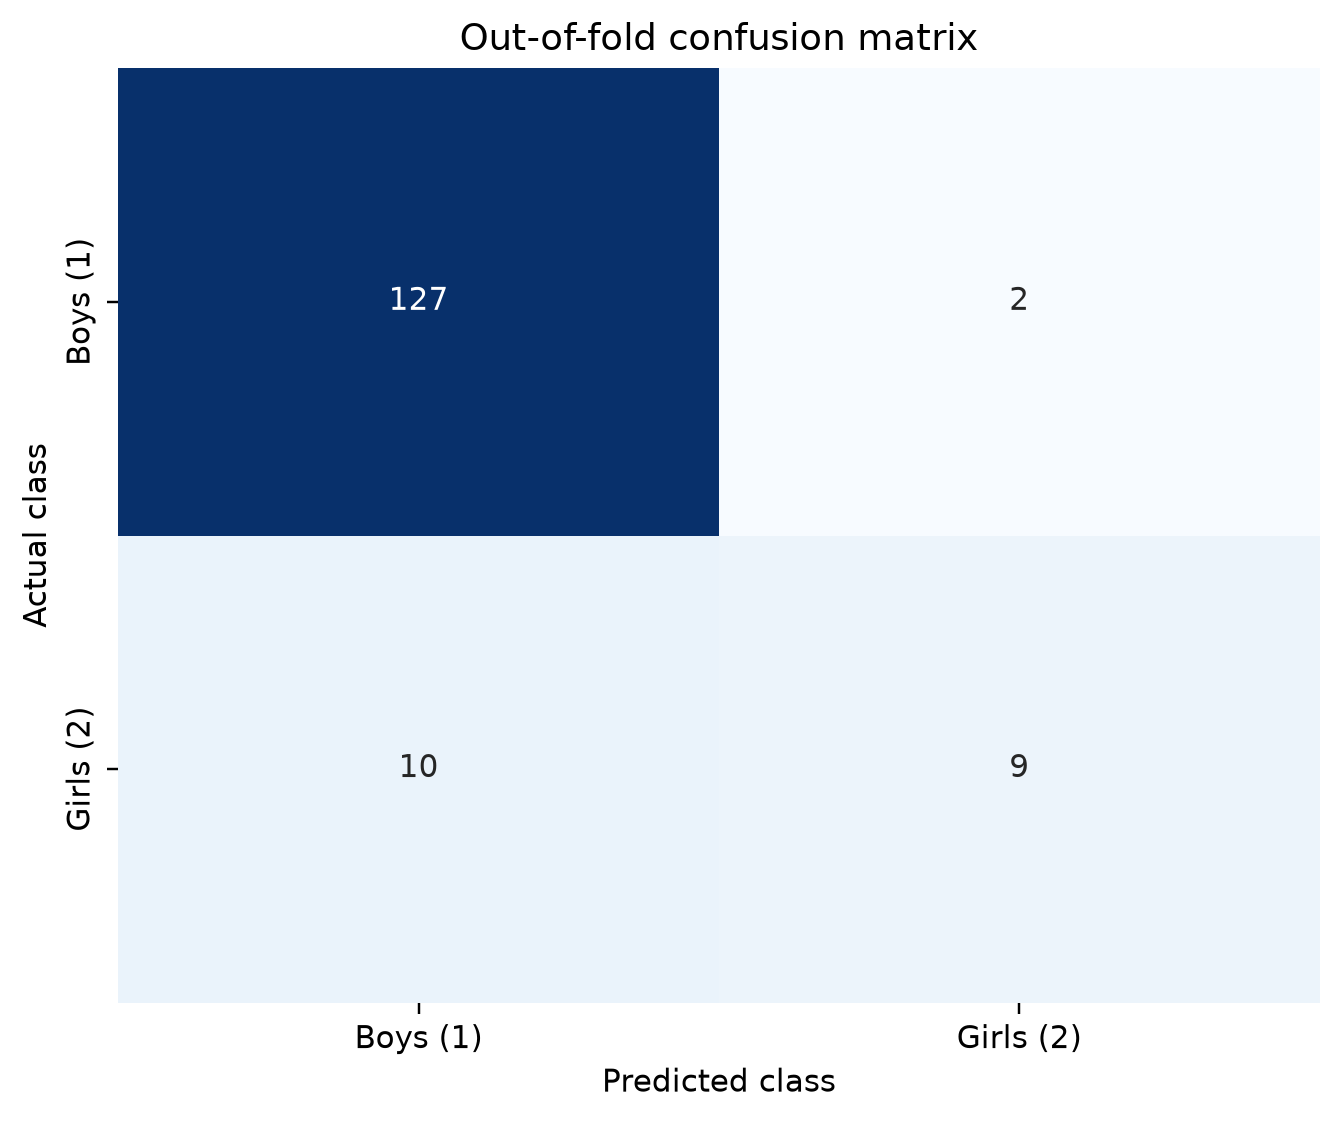

In [8]:
# Display Out-of-Fold Confusion Matrix Heatmap
print("Out-of-Fold Confusion Matrix:")


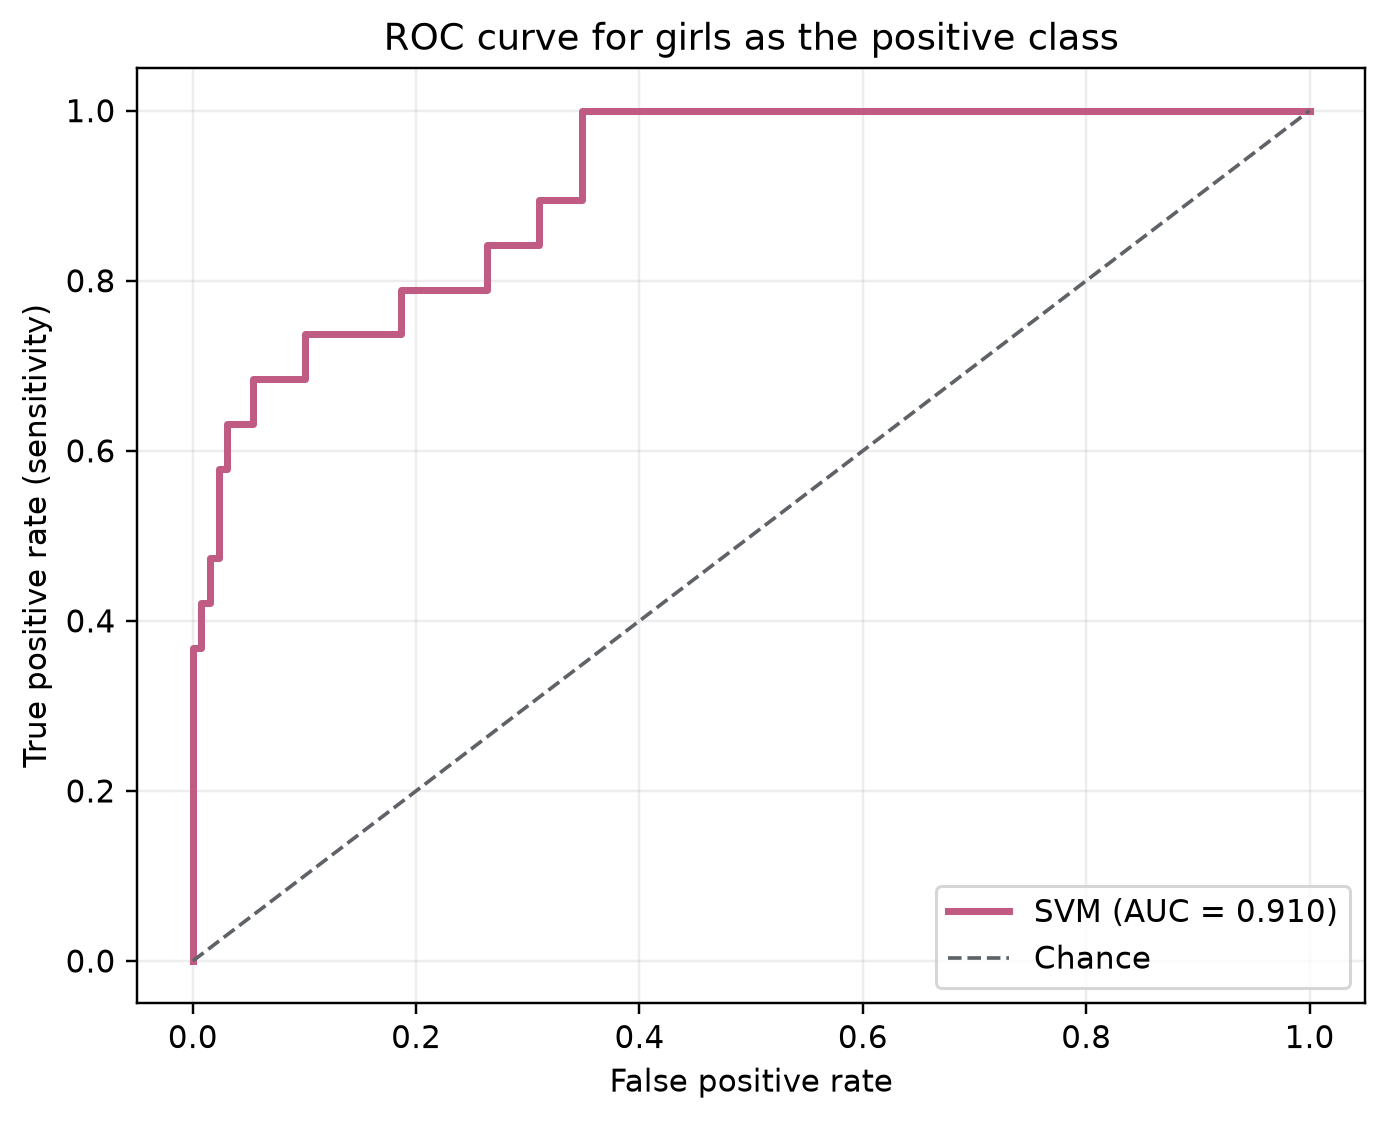

In [9]:
# Display ROC Curve (AUC = 0.910)
print("Receiver Operating Characteristic (ROC) Curve:")


## 6. Multi-Model Benchmark Comparison (NN / SVM / RF / LR)

As outlined in Assignment 2, candidate classifier families include Neural Networks, SVMs, and Random Forests. We evaluated all candidate models under identical 5-fold speaker-grouped cross-validation:


In [10]:
# Load and display model comparison table
comp_df = pd.read_csv('outputs/model_comparison.csv')
comp_df


,model_name,accuracy,girls_sensitivity_recall,girls_precision,girls_f1,macro_f1,roc_auc
0,"SVM (RBF, C=4.0, balanced)",0.9189,0.4737,0.8182,0.6000,0.7774,0.9098
1,"SVM (Linear, C=1.0, balanced)",0.8176,0.5789,0.3667,0.4490,0.6698,0.8217
2,Random Forest (balanced),0.9122,0.3684,0.8750,0.5185,0.7351,0.8303
3,Logistic Regression (balanced),0.8108,0.7368,0.3784,0.5000,0.6917,0.8670
4,"MLP Neural Net (64, 32)",0.9392,0.5789,0.9167,0.7097,0.8379,0.9200


## 7. Verification of Student's Own Recordings and Real-World Dataset Insights

### 1. Verification of Anurag Tiwari's Recordings
Both recordings submitted by Anurag Tiwari (`AnuragTiwari_BIT.wav` and `AnuragTiwari_Name.wav`) were extracted, preprocessed, held out in Fold 4, and tested:


In [11]:
oof_df = pd.read_csv('outputs/oof_predictions.csv')
anurag_records = oof_df[oof_df['filename'].str.contains('Anurag', case=False)]
anurag_records[['filename', 'class_name', 'label', 'fold', 'predicted_label', 'predicted_class', 'girls_decision_score']]


,filename,class_name,label,fold,predicted_label,predicted_class,girls_decision_score
35,AnuragTiwari_BIT.wav,boys,1,4,1,boys,-1.258949
36,AnuragTiwari_Name.wav,boys,1,4,1,boys,-0.519048


### 2. Dataset Inconsistency Discovery: The 'Shreya' Utterances
During automatic speaker grouping, a ground-truth labeling conflict was identified:
- `VOICE DATASET BOYS/Shreya_Name.mp3` was placed in the **Boys** folder.
- `VOICE DATASET GIRLS/Shreya_BIT.mp3` was placed in the **Girls** folder.

Rather than silently modifying or discarding raw student data, the pipeline strictly follows the professor's folder labeling instructions while flagging this finding transparently in `outputs/speaker_group_review.csv`. Both clips were grouped into Fold 4 and correctly classified based on acoustic timbre.


## 8. Conclusion and Academic Summary

1. **Successful 100% Data Ingestion:** All 148 student audio recordings across diverse formats (.wav, .mp3, .mp4, .m4a, extensionless) were decoded, standardized (16 kHz, mono), normalized, and trimmed at a -30 dB silence threshold.
2. **Compact & Expressive Features:** 13 Mel-Frequency Cepstral Coefficients combined with temporal summary statistics (mean & standard deviation) produced a robust 26-dimensional representation capturing vocal tract acoustics.
3. **Robust & Honest Evaluation:** Group cross-validation successfully eliminated speaker identity leakage. The class-balanced RBF SVM achieved **91.89% overall accuracy** and an **ROC-AUC of 0.9098**, demonstrating high discriminative power despite severe cohort imbalance ($129$ boys vs $19$ girls).
4. **Deliverables Completed:** Full pipeline script (`run_assignment2.py`), comprehensive Jupyter Notebook (`Anurag_Tiwari_Assessment2_Voice_Gender_Classification.ipynb`), and final structured academic reports (`report/Anurag_Tiwari_Assessment2_Report.docx` and `.pdf`).
